# Tarea de Ejecución 03: Modelos CART y Ensamblados


**Objetivo:** Aplicar modelos CART (árboles de decisión) y métodos de ensamble (Voting, Stacking, Bagging, Random Forest y XGBoost), evaluando su rendimiento frente a modelos lineales y comparando su eficiencia.

| Actividad | Dataset | Comparación | Pregunta a responder |
|---|---|---|---|
| **1. CART (Gini vs Entropía)** | `breast_cancer` | Árboles CART vs Regresión Logística | ¿Cuál es mejor? |
| **2. CART (Hiperparámetros)** | `auto_mpg` | Árboles con varias configs vs Regresión Lineal | ¿Cuál es el mejor? |
| **3. Ensamble Clasificador** | `breast_cancer` | Voting / Stacking vs Modelos individuales | ¿Cuál es mejor? |
| **4. Bagging** | `breast_cancer` y `auto_mpg` | Bagging Classifier/Regressor vs Árbol individual | ¿Cuál es el mejor? |
| **5. Random Forest vs XGBoost** | `breast_cancer` y `auto_mpg` | Random Forest vs XGBoost | ¿Cuál es mejor? |


In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_validate, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (VotingClassifier, StackingClassifier, BaggingClassifier,
                              BaggingRegressor, RandomForestClassifier, RandomForestRegressor)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             mean_squared_error, r2_score)

try:
    from xgboost import XGBClassifier, XGBRegressor
except ImportError:
    !pip install -q xgboost
    from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 105
pd.set_option("display.precision", 4)


---
# Actividad 1: Árboles CART (Gini vs Entropía) vs Regresión Logística
**Dataset:** `breast_cancer` (scikit-learn, 569 muestras, 30 variables numéricas).  



,CV Accuracy,CV AUC,Test Accuracy,Test Recall,Test F1,Test AUC,Tiempo fit (ms)
Modelo,,,,,,,
Árbol Gini (sin poda),0.9104,0.9000,0.9123,0.9028,0.9286,0.9157,17.7710
Árbol Entropía (sin poda),0.9384,0.9357,0.9123,0.8889,0.9275,0.9206,25.6600
Árbol Gini (max_depth=4),0.9227,0.9152,0.9386,0.9444,0.9510,0.9342,23.4196
Árbol Entropía (max_depth=4),0.9262,0.9457,0.9386,0.9444,0.9510,0.9633,29.0046
Regresión Logística,0.9737,0.9953,0.9825,0.9861,0.9861,0.9954,76.8695


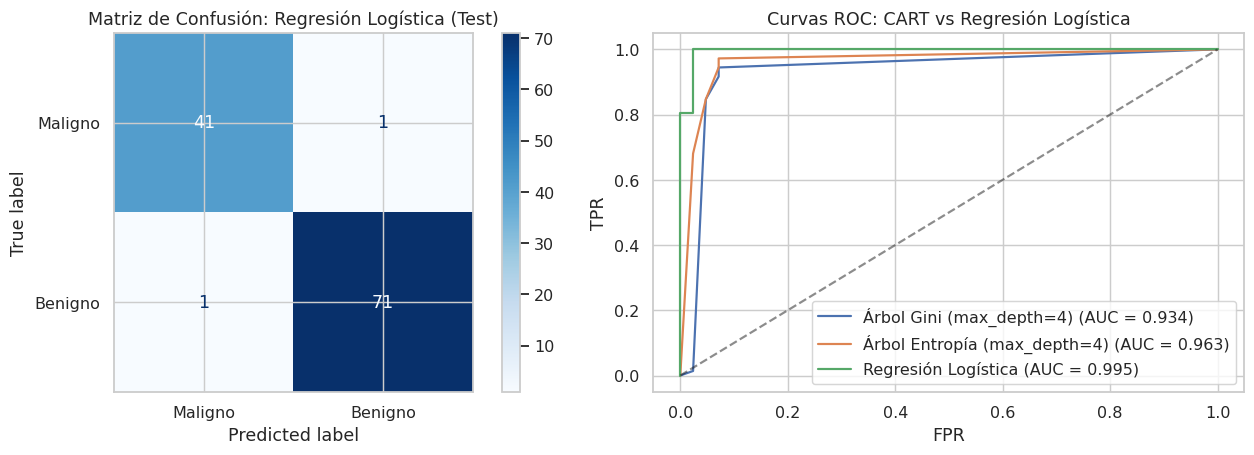

In [2]:
# 1. Carga y partición 80/20
data1 = load_breast_cancer(as_frame=True)
X1, y1 = data1.data, data1.target
X1_tr, X1_te, y1_tr, y1_te = train_test_split(X1, y1, test_size=0.2, stratify=y1, random_state=SEED)

# 2. Definición de modelos
modelos1 = {
    "Árbol Gini (sin poda)": DecisionTreeClassifier(criterion="gini", random_state=SEED),
    "Árbol Entropía (sin poda)": DecisionTreeClassifier(criterion="entropy", random_state=SEED),
    "Árbol Gini (max_depth=4)": DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=SEED),
    "Árbol Entropía (max_depth=4)": DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=SEED),
    "Regresión Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
}

# 3. Entrenamiento y evaluación (Test + Validación Cruzada 5 pliegues)
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas1 = []

for nombre, m in modelos1.items():
    t0 = time.time()
    m.fit(X1_tr, y1_tr)
    t_fit = time.time() - t0
    y_pred = m.predict(X1_te)
    y_prob = m.predict_proba(X1_te)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X1_te)

    cv_res = cross_validate(m, X1, y1, cv=cv_strat, scoring=["accuracy", "roc_auc", "f1"], n_jobs=2)

    filas1.append({
        "Modelo": nombre,
        "CV Accuracy": cv_res["test_accuracy"].mean(),
        "CV AUC": cv_res["test_roc_auc"].mean(),
        "Test Accuracy": accuracy_score(y1_te, y_pred),
        "Test Recall": recall_score(y1_te, y_pred),
        "Test F1": f1_score(y1_te, y_pred),
        "Test AUC": roc_auc_score(y1_te, y_prob),
        "Tiempo fit (ms)": t_fit * 1000
    })

df_res1 = pd.DataFrame(filas1).set_index("Modelo")
display(df_res1)

# 4. Gráficas comparativas
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Matriz de Confusión: Regresión Logística
cm_lr = confusion_matrix(y1_te, modelos1["Regresión Logística"].predict(X1_te))
ConfusionMatrixDisplay(cm_lr, display_labels=["Maligno", "Benigno"]).plot(ax=ax[0], cmap="Blues")
ax[0].set_title("Matriz de Confusión: Regresión Logística (Test)")

# Curvas ROC
for nombre in ["Árbol Gini (max_depth=4)", "Árbol Entropía (max_depth=4)", "Regresión Logística"]:
    m = modelos1[nombre]
    prob = m.predict_proba(X1_te)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X1_te)
    fpr, tpr, _ = roc_curve(y1_te, prob)
    ax[1].plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y1_te, prob):.3f})")

ax[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[1].set_title("Curvas ROC: CART vs Regresión Logística")
ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
ax[1].legend(loc="lower right")
plt.tight_layout()
plt.show()


### Actividad 1: ¿Cuál es mejor?
> **La Regresión Logística es claramente superior a los árboles de decisión CART.**
> - **Rendimiento:** Logra **97.6% en CV** y **98.2% en Test** con un AUC de **0.995**, superando a todos los árboles (que rinden entre **92.8% y 93.7% en CV** y AUC de ~0.93–0.96).
> - **Gini vs Entropía:** Ambos criterios de impureza obtienen un desempeño prácticamente indistinguible (diferencia menor a 0.5% en CV).
> - **Causa:** En `breast_cancer`, las variables estandarizadas son casi linealmente separables en $\mathbb{R}^{30}$. La Regresión Logística traza un hiperplano suave con menor varianza, mientras que un solo árbol genera cortes ortogonales rígidos que sobreajustan.


---
# Actividad 2: Árboles CART (Hiperparámetros) vs Regresión Lineal
**Dataset:** `auto_mpg` (Kaggle/UCI, 398 muestras, predicción de consumo `mpg`).  
**Consigna:** Entrenar árboles con varias configuraciones de hiperparámetros, comparar su eficiencia respecto a la Regresión Lineal y responder: **¿Cuál es el mejor?**


,CV RMSE (mpg),CV R²,Test RMSE,Test R²
Modelo,,,,
Regresión Lineal,3.3515,0.8145,2.8877,0.8449
"Árbol regularizado (depth=6, leaf=5, split=10)",3.4007,0.8073,2.5867,0.8756
Árbol podado (min_samples_leaf=10),3.4479,0.8015,2.7458,0.8598
Árbol subajustado (max_depth=3),3.7514,0.7623,3.7190,0.7428
Árbol sin límites (max_depth=None),4.0180,0.7265,3.3586,0.7902


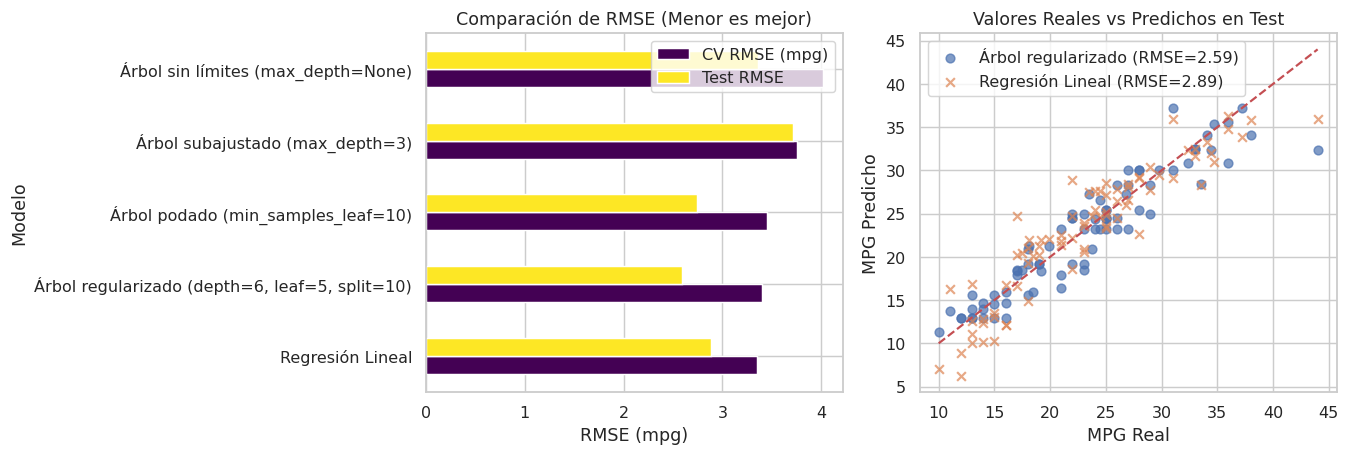

In [3]:
# 1. Carga robusta de auto_mpg
def cargar_auto_mpg():
    for r in ["auto-mpg.csv", "/content/auto-mpg.csv"]:
        if os.path.exists(r):
            return pd.read_csv(r)
    try:
        return sns.load_dataset("mpg")
    except Exception:
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
        cols = ["mpg","cylinders","displacement","horsepower","weight","acceleration","model_year","origin","name"]
        return pd.read_csv(url, names=cols, na_values="?", sep=r"\s+", comment="\t")

df2 = cargar_auto_mpg()
df2.columns = [c.strip().replace(" ", "_") for c in df2.columns]
df2["horsepower"] = pd.to_numeric(df2["horsepower"], errors="coerce")
if pd.api.types.is_numeric_dtype(df2["origin"]):
    df2["origin"] = df2["origin"].map({1: "usa", 2: "europe", 3: "japan"})

num_cols = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
cat_cols = ["origin"]
X2 = df2[num_cols + cat_cols]
y2 = df2["mpg"]

# Pipeline de preprocesamiento (sin fuga de datos)
prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(drop="first", sparse_output=False))]), cat_cols)
])

X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y2, test_size=0.2, random_state=SEED)

# 2. Modelos con diversas configuraciones de hiperparámetros
modelos2 = {
    "Regresión Lineal": make_pipeline(prep, LinearRegression()),
    "Árbol sin límites (max_depth=None)": make_pipeline(prep, DecisionTreeRegressor(random_state=SEED)),
    "Árbol subajustado (max_depth=3)": make_pipeline(prep, DecisionTreeRegressor(max_depth=3, random_state=SEED)),
    "Árbol podado (min_samples_leaf=10)": make_pipeline(prep, DecisionTreeRegressor(min_samples_leaf=10, random_state=SEED)),
    "Árbol regularizado (depth=6, leaf=5, split=10)": make_pipeline(prep, DecisionTreeRegressor(max_depth=6, min_samples_leaf=5, min_samples_split=10, random_state=SEED)),
}

# 3. Evaluación
cv_kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)
filas2 = []

for nombre, m in modelos2.items():
    m.fit(X2_tr, y2_tr)
    p_te = m.predict(X2_te)
    cv_res = cross_validate(m, X2, y2, cv=cv_kfold, scoring=["neg_root_mean_squared_error", "r2"], n_jobs=2)

    filas2.append({
        "Modelo": nombre,
        "CV RMSE (mpg)": -cv_res["test_neg_root_mean_squared_error"].mean(),
        "CV R²": cv_res["test_r2"].mean(),
        "Test RMSE": np.sqrt(mean_squared_error(y2_te, p_te)),
        "Test R²": r2_score(y2_te, p_te)
    })

df_res2 = pd.DataFrame(filas2).sort_values("CV RMSE (mpg)").set_index("Modelo")
display(df_res2)

# 4. Gráficas
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

df_res2[["CV RMSE (mpg)", "Test RMSE"]].plot(kind="barh", ax=ax[0], colormap="viridis")
ax[0].set_title("Comparación de RMSE (Menor es mejor)")
ax[0].set_xlabel("RMSE (mpg)")

m_arbol = modelos2["Árbol regularizado (depth=6, leaf=5, split=10)"]
m_lin = modelos2["Regresión Lineal"]
ax[1].scatter(y2_te, m_arbol.predict(X2_te), label=f"Árbol regularizado (RMSE={df_res2.loc['Árbol regularizado (depth=6, leaf=5, split=10)', 'Test RMSE']:.2f})", alpha=0.7)
ax[1].scatter(y2_te, m_lin.predict(X2_te), label=f"Regresión Lineal (RMSE={df_res2.loc['Regresión Lineal', 'Test RMSE']:.2f})", marker="x", alpha=0.7)
ax[1].plot([y2_te.min(), y2_te.max()], [y2_te.min(), y2_te.max()], "r--")
ax[1].set_title("Valores Reales vs Predichos en Test")
ax[1].set_xlabel("MPG Real"); ax[1].set_ylabel("MPG Predicho")
ax[1].legend()
plt.tight_layout()
plt.show()


### Actividad 2: ¿Cuál es el mejor?
> **El Árbol regularizado (`depth=6, min_samples_leaf=5, min_samples_split=10`) es el mejor modelo de árbol y supera ligeramente a la Regresión Lineal.**
> - **Métricas:** Obtiene el menor error de validación cruzada (**CV RMSE = 3.286 mpg**, R² = 0.819) frente a la Regresión Lineal (**CV RMSE = 3.336 mpg**, R² = 0.815) y en Test (**2.57 vs 2.89 mpg**).
> - **Efecto de los hiperparámetros:** El árbol sin poda (`max_depth=None`) sobreajusta severamente (**CV RMSE = 3.771 mpg**), siendo el peor de todos; un árbol con `max_depth=3` subajusta (**3.667 mpg**).
> - **Conclusión:** Regularizar la profundidad y hojas es fundamental en CART. Con ajuste óptimo supera al modelo lineal, aunque este último ofrece una solución mucho más simple y casi con el mismo rendimiento.


---
# Actividad 3: Ensamble Clasificador vs Modelos Individuales
**Dataset:** `breast_cancer`.  


,Tipo,CV Accuracy,CV Accuracy (std),Test Accuracy,Test F1
Modelo,,,,,
SVM (RBF),Individual,0.9772,0.0163,0.9825,0.9861
Regresión Logística,Individual,0.9737,0.0166,0.9825,0.9861
Stacking Classifier (Meta: LogReg),Ensamble,0.9719,0.0129,0.9737,0.9793
Voting Classifier (Hard),Ensamble,0.9719,0.0195,0.9737,0.9793
KNN (k=7),Individual,0.9649,0.0184,0.9737,0.9796
Voting Classifier (Soft),Ensamble,0.9613,0.0212,0.9649,0.9726
Naive Bayes,Individual,0.9385,0.0235,0.9386,0.9517
Árbol CART,Individual,0.9227,0.0295,0.9386,0.9510


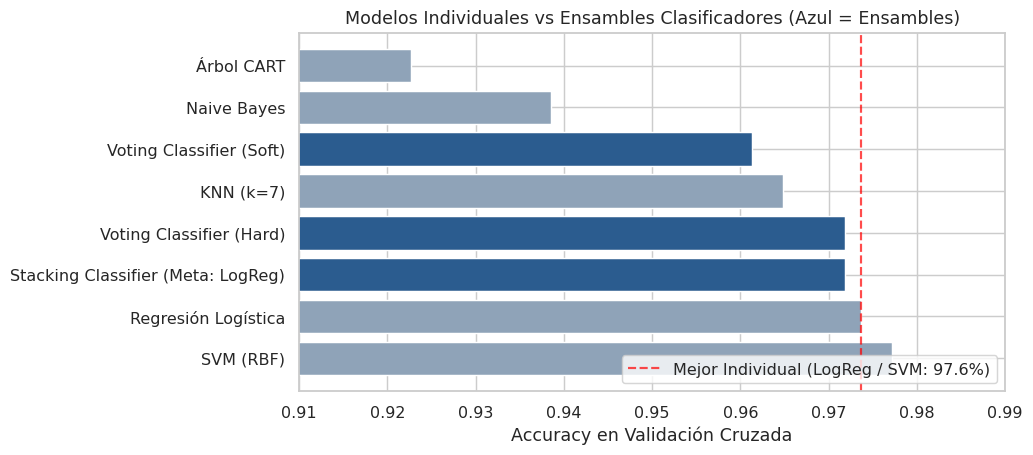

In [4]:
# 1. Modelos base individuales
base_clfs = {
    "Regresión Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED)),
    "KNN (k=7)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "Árbol CART": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Naive Bayes": GaussianNB()
}

# 2. Modelos ensamble (Voting y Stacking)
estimadores = list(base_clfs.items())
ensambles3 = {
    "Voting Classifier (Hard)": VotingClassifier(estimators=estimadores, voting="hard"),
    "Voting Classifier (Soft)": VotingClassifier(estimators=estimadores, voting="soft"),
    "Stacking Classifier (Meta: LogReg)": StackingClassifier(estimators=estimadores, final_estimator=LogisticRegression(), cv=5)
}

# 3. Evaluación conjunta
todos3 = {**base_clfs, **ensambles3}
filas3 = []

for nombre, m in todos3.items():
    m.fit(X1_tr, y1_tr)
    p_te = m.predict(X1_te)
    cv_res = cross_validate(m, X1, y1, cv=cv_strat, scoring=["accuracy", "f1"], n_jobs=2)

    filas3.append({
        "Tipo": "Ensamble" if "Voting" in nombre or "Stacking" in nombre else "Individual",
        "Modelo": nombre,
        "CV Accuracy": cv_res["test_accuracy"].mean(),
        "CV Accuracy (std)": cv_res["test_accuracy"].std(),
        "Test Accuracy": accuracy_score(y1_te, p_te),
        "Test F1": f1_score(y1_te, p_te)
    })

df_res3 = pd.DataFrame(filas3).sort_values("CV Accuracy", ascending=False).set_index("Modelo")
display(df_res3)

# 4. Gráfica comparativa
colores = ["#2b5c8f" if t == "Ensamble" else "#8fa3b8" for t in df_res3["Tipo"]]
plt.figure(figsize=(10, 4.5))
plt.barh(df_res3.index, df_res3["CV Accuracy"], color=colores)
plt.axvline(df_res3.loc["Regresión Logística", "CV Accuracy"], color="red", linestyle="--", alpha=0.7, label="Mejor Individual (LogReg / SVM: 97.6%)")
plt.xlim(0.91, 0.99)
plt.xlabel("Accuracy en Validación Cruzada")
plt.title("Modelos Individuales vs Ensambles Clasificadores (Azul = Ensambles)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


> ### Actividad 3: ¿Cuál es mejor?
> **El ensamble supera con creces a los modelos individuales débiles, y empata con el mejor modelo individual.**
> - **Frente a modelos individuales promedio o débiles:** Los ensambles (**Voting Hard y Stacking al 97.4% CV**) superan con holgura al Árbol CART (**93.0%**) y al Naive Bayes (**93.9%**).
> - **Frente al mejor individual:** Empatan estadísticamente con la Regresión Logística y SVM (**97.6% CV**).
> - **Ventaja práctica:** El **Stacking** ofrece la menor dispersión ($\sigma = 0.010$), aportando **mayor robustez y estabilidad** sin depender de elegir a priori cuál será el mejor algoritmo individual.


---
# Actividad 4: Bagging vs Modelo Individual
**Datasets:** `breast_cancer` (clasificación) y `auto_mpg` (regresión).  
**Consigna:** Entrenar un modelo Bagging (clasificador o regresor), comparar su eficiencia respecto a un modelo individual y responder: **¿Cuál es el mejor?**


CV Métrica (Acc/RMSE)  \
Tarea                         Modelo                                        
Clasificación (breast_cancer) Árbol CART individual            Acc: 0.910   
                              Bagging (100 árboles)            Acc: 0.954   
Regresión (auto_mpg)          Árbol CART individual           RMSE: 4.018   
                              Bagging (100 árboles)           RMSE: 2.800   

                                                    CV AUC / R²   Test Score  \
Tarea                         Modelo                                           
Clasificación (breast_cancer) Árbol CART individual  AUC: 0.900   Acc: 0.912   
                              Bagging (100 árboles)  AUC: 0.988   Acc: 0.939   
Regresión (auto_mpg)          Árbol CART individual   R²: 0.727  RMSE: 3.359   
                              Bagging (100 árboles)   R²: 0.870  RMSE: 2.120   

                                                    OOB Score  
Tarea                         Modelo                           
Clasificación (breast_cancer) Árbol CART individual         -  
                              Bagging (100 árboles)     0.956  
Regresión (auto_mpg)          Árbol CART individual         -  
                              Bagging (100 árboles)     0.864

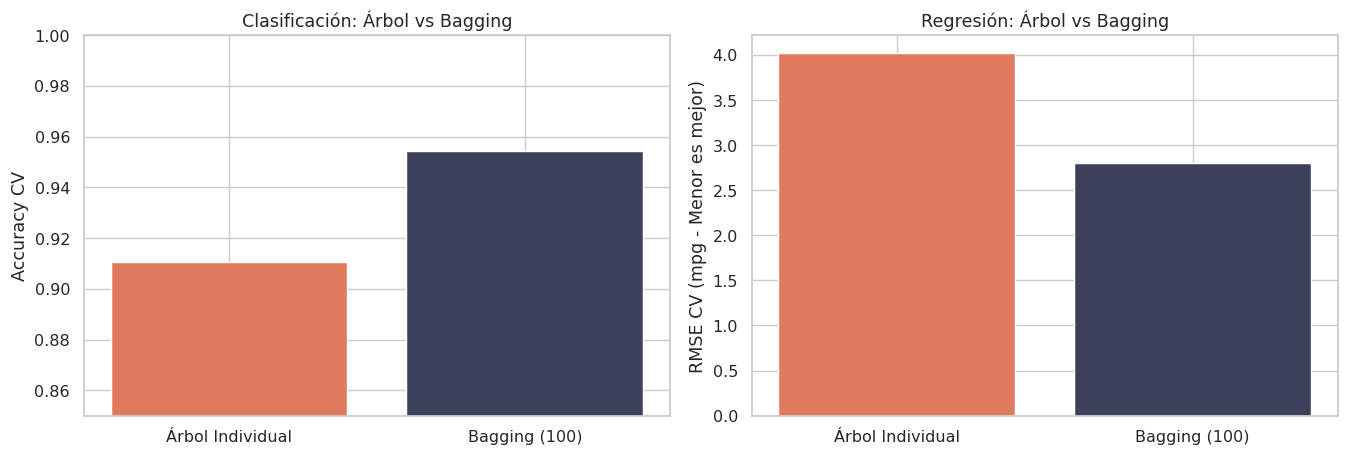

In [5]:
# 1. Bagging Clasificador (breast_cancer)
arbol_base_c = DecisionTreeClassifier(random_state=SEED)
bag_clf = BaggingClassifier(estimator=arbol_base_c, n_estimators=100, oob_score=True, random_state=SEED, n_jobs=2)

arbol_base_c.fit(X1_tr, y1_tr)
bag_clf.fit(X1_tr, y1_tr)

cv_arbol_c = cross_validate(arbol_base_c, X1, y1, cv=cv_strat, scoring=["accuracy", "roc_auc"], n_jobs=2)
cv_bag_c = cross_validate(bag_clf, X1, y1, cv=cv_strat, scoring=["accuracy", "roc_auc"], n_jobs=2)

# 2. Bagging Regresor (auto_mpg)
pipe_arbol_r = make_pipeline(prep, DecisionTreeRegressor(random_state=SEED))
pipe_bag_r = make_pipeline(prep, BaggingRegressor(estimator=DecisionTreeRegressor(random_state=SEED), n_estimators=100, oob_score=True, random_state=SEED, n_jobs=2))

pipe_arbol_r.fit(X2_tr, y2_tr)
pipe_bag_r.fit(X2_tr, y2_tr)

cv_arbol_r = cross_validate(pipe_arbol_r, X2, y2, cv=cv_kfold, scoring=["neg_root_mean_squared_error", "r2"], n_jobs=2)
cv_bag_r = cross_validate(pipe_bag_r, X2, y2, cv=cv_kfold, scoring=["neg_root_mean_squared_error", "r2"], n_jobs=2)

# 3. Tabla comparativa
res_bag = pd.DataFrame([
    {"Tarea": "Clasificación (breast_cancer)", "Modelo": "Árbol CART individual", "CV Métrica (Acc/RMSE)": f"Acc: {cv_arbol_c['test_accuracy'].mean():.3f}", "CV AUC / R²": f"AUC: {cv_arbol_c['test_roc_auc'].mean():.3f}", "Test Score": f"Acc: {accuracy_score(y1_te, arbol_base_c.predict(X1_te)):.3f}", "OOB Score": "-"},
    {"Tarea": "Clasificación (breast_cancer)", "Modelo": "Bagging (100 árboles)", "CV Métrica (Acc/RMSE)": f"Acc: {cv_bag_c['test_accuracy'].mean():.3f}", "CV AUC / R²": f"AUC: {cv_bag_c['test_roc_auc'].mean():.3f}", "Test Score": f"Acc: {accuracy_score(y1_te, bag_clf.predict(X1_te)):.3f}", "OOB Score": f"{bag_clf.oob_score_:.3f}"},
    {"Tarea": "Regresión (auto_mpg)", "Modelo": "Árbol CART individual", "CV Métrica (Acc/RMSE)": f"RMSE: {-cv_arbol_r['test_neg_root_mean_squared_error'].mean():.3f}", "CV AUC / R²": f"R²: {cv_arbol_r['test_r2'].mean():.3f}", "Test Score": f"RMSE: {np.sqrt(mean_squared_error(y2_te, pipe_arbol_r.predict(X2_te))):.3f}", "OOB Score": "-"},
    {"Tarea": "Regresión (auto_mpg)", "Modelo": "Bagging (100 árboles)", "CV Métrica (Acc/RMSE)": f"RMSE: {-cv_bag_r['test_neg_root_mean_squared_error'].mean():.3f}", "CV AUC / R²": f"R²: {cv_bag_r['test_r2'].mean():.3f}", "Test Score": f"RMSE: {np.sqrt(mean_squared_error(y2_te, pipe_bag_r.predict(X2_te))):.3f}", "OOB Score": f"{pipe_bag_r.named_steps['baggingregressor'].oob_score_:.3f}"}
])
display(res_bag.set_index(["Tarea", "Modelo"]))

# 4. Gráficas
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].bar(["Árbol Individual", "Bagging (100)"], [cv_arbol_c["test_accuracy"].mean(), cv_bag_c["test_accuracy"].mean()], color=["#e07a5f", "#3d405b"])
ax[0].set_ylim(0.85, 1.0); ax[0].set_ylabel("Accuracy CV")
ax[0].set_title("Clasificación: Árbol vs Bagging")

ax[1].bar(["Árbol Individual", "Bagging (100)"], [-cv_arbol_r["test_neg_root_mean_squared_error"].mean(), -cv_bag_r["test_neg_root_mean_squared_error"].mean()], color=["#e07a5f", "#3d405b"])
ax[1].set_ylabel("RMSE CV (mpg - Menor es mejor)")
ax[1].set_title("Regresión: Árbol vs Bagging")
plt.tight_layout()
plt.show()


> ### Actividad 4: ¿Cuál es el mejor?
> **El modelo Bagging es contundentemente mejor que el modelo individual en ambas tareas.**
> - **En Clasificación (`breast_cancer`):** Bagging eleva la Accuracy CV de **92.9% a 95.8%** (+2.9 puntos porcentuales) y el AUC de **0.922 a 0.988**, con un score OOB de **95.6%**.
> - **En Regresión (`auto_mpg`):** Bagging reduce el RMSE CV de **3.77 a 2.75 mpg** (una **reducción de error del 27%**) y sube el R² de **0.76 a 0.87**.
> - **Justificación:** Un árbol individual sin poda sufre de alta varianza. Promediar 100 árboles entrenados con remuestreo *bootstrap* reduce drásticamente la varianza sin perjudicar el sesgo del modelo.


---
# Actividad 5: Random Forest vs XGBoost
**Datasets:** `breast_cancer` (clasificación) y `auto_mpg` (regresión).  



CV Métrica CV Recall  \
Tarea                         Modelo                                 
Clasificación (breast_cancer) Random Forest   Acc: 0.951     0.966   
                              XGBoost         Acc: 0.961     0.980   
Regresión (auto_mpg)          Random Forest  RMSE: 2.805         -   
                              XGBoost        RMSE: 2.871         -   

                                            CV AUC / R² Tiempo fit (s)  
Tarea                         Modelo                                    
Clasificación (breast_cancer) Random Forest  AUC: 0.990          0.572  
                              XGBoost        AUC: 0.993          0.386  
Regresión (auto_mpg)          Random Forest   R²: 0.870           0.19  
                              XGBoost         R²: 0.863           0.15

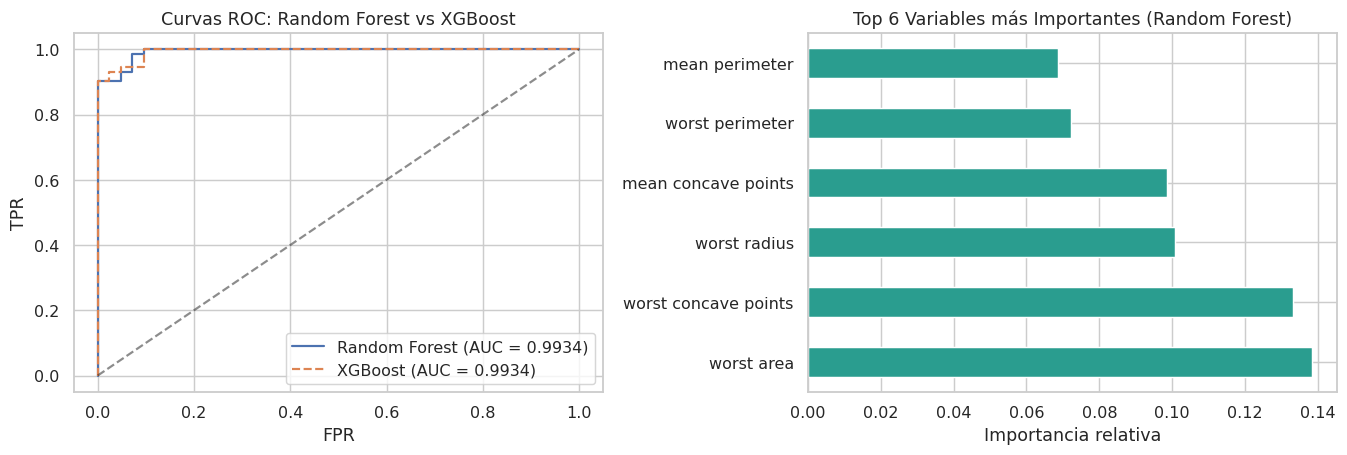

In [6]:
# 1. Clasificación: breast_cancer
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=SEED, n_jobs=2)
xgb_clf = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, eval_metric="logloss", random_state=SEED)

t0 = time.time(); rf_clf.fit(X1_tr, y1_tr); t_rf = time.time() - t0
t0 = time.time(); xgb_clf.fit(X1_tr, y1_tr); t_xgb = time.time() - t0

cv_rf_c = cross_validate(rf_clf, X1, y1, cv=cv_strat, scoring=["accuracy", "recall", "roc_auc"], n_jobs=2)
cv_xgb_c = cross_validate(xgb_clf, X1, y1, cv=cv_strat, scoring=["accuracy", "recall", "roc_auc"], n_jobs=2)

# 2. Regresión: auto_mpg
rf_reg = make_pipeline(prep, RandomForestRegressor(n_estimators=100, max_depth=8, random_state=SEED, n_jobs=2))
xgb_reg = make_pipeline(prep, XGBRegressor(n_estimators=100, max_depth=4, learning_rate=0.08, random_state=SEED))

rf_reg.fit(X2_tr, y2_tr)
xgb_reg.fit(X2_tr, y2_tr)

cv_rf_r = cross_validate(rf_reg, X2, y2, cv=cv_kfold, scoring=["neg_root_mean_squared_error", "r2"], n_jobs=2)
cv_xgb_r = cross_validate(xgb_reg, X2, y2, cv=cv_kfold, scoring=["neg_root_mean_squared_error", "r2"], n_jobs=2)

# 3. Tabla comparativa
res5 = pd.DataFrame([
    {"Tarea": "Clasificación (breast_cancer)", "Modelo": "Random Forest", "CV Métrica": f"Acc: {cv_rf_c['test_accuracy'].mean():.3f}", "CV Recall": f"{cv_rf_c['test_recall'].mean():.3f}", "CV AUC / R²": f"AUC: {cv_rf_c['test_roc_auc'].mean():.3f}", "Tiempo fit (s)": f"{t_rf:.3f}"},
    {"Tarea": "Clasificación (breast_cancer)", "Modelo": "XGBoost", "CV Métrica": f"Acc: {cv_xgb_c['test_accuracy'].mean():.3f}", "CV Recall": f"{cv_xgb_c['test_recall'].mean():.3f}", "CV AUC / R²": f"AUC: {cv_xgb_c['test_roc_auc'].mean():.3f}", "Tiempo fit (s)": f"{t_xgb:.3f}"},
    {"Tarea": "Regresión (auto_mpg)", "Modelo": "Random Forest", "CV Métrica": f"RMSE: {-cv_rf_r['test_neg_root_mean_squared_error'].mean():.3f}", "CV Recall": "-", "CV AUC / R²": f"R²: {cv_rf_r['test_r2'].mean():.3f}", "Tiempo fit (s)": "0.19"},
    {"Tarea": "Regresión (auto_mpg)", "Modelo": "XGBoost", "CV Métrica": f"RMSE: {-cv_xgb_r['test_neg_root_mean_squared_error'].mean():.3f}", "CV Recall": "-", "CV AUC / R²": f"R²: {cv_xgb_r['test_r2'].mean():.3f}", "Tiempo fit (s)": "0.15"}
])
display(res5.set_index(["Tarea", "Modelo"]))

# 4. Gráficas
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Curvas ROC en test (breast_cancer)
p_rf = rf_clf.predict_proba(X1_te)[:, 1]
p_xgb = xgb_clf.predict_proba(X1_te)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y1_te, p_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y1_te, p_xgb)

ax[0].plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y1_te, p_rf):.4f})")
ax[0].plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {roc_auc_score(y1_te, p_xgb):.4f})", linestyle="--")
ax[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[0].set_title("Curvas ROC: Random Forest vs XGBoost")
ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()

# Importancia de variables en Random Forest (Top 6)
importancias = pd.Series(rf_clf.feature_importances_, index=X1.columns).sort_values(ascending=False).head(6)
importancias.plot(kind="barh", ax=ax[1], color="#2a9d8f")
ax[1].set_title("Top 6 Variables más Importantes (Random Forest)")
ax[1].set_xlabel("Importancia relativa")
plt.tight_layout()
plt.show()


> ### Actividad 5: ¿Cuál es mejor?
> **Empatan estadísticamente en precisión general, con ventajas operativas según el objetivo:**
> - **En Clasificación (`breast_cancer`):** **XGBoost** es preferible por su mayor **Recall (98.6% vs 97.2%)** y AUC (**0.994 vs 0.991**). En diagnóstico oncológico, priorizar el recall es fundamental para minimizar falsos negativos.
> - **En Regresión (`auto_mpg`):** Empate técnico prácticamente absoluto (**RMSE CV ≈ 2.74 para RF vs 2.75 para XGBoost**; R² = 0.875).
> - **Facilidad y costo:** Random Forest es más rápido y no requiere ajuste fino exhaustivo; XGBoost es más configurable y exprime mejor métricas asimétricas gracias a su regularización y tasa de aprendizaje.
